# 1. Découvete et Manipulation de la base MNIST

#### Chargement des bibliothèques nécessaires

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.neural_network import MLPClassifier
import warnings

#### Chargement des données

In [2]:
data_test = pd.read_csv("mnist_test.csv")
data_train = pd.read_csv("mnist_train.csv")

print(f"Dimension de data_test : {data_test.shape}")
print(f"Dimension de data_train : {data_train.shape}")

Dimension de data_test : (10000, 785)
Dimension de data_train : (60000, 785)


In [3]:

# Extraction des étiquettes (première colonne)
y_train = data_train.iloc[:, 0].to_numpy()
y_test = data_test.iloc[:, 0].to_numpy()

# Extraction des images (toutes les colonnes sauf la première)
X_train = data_train.iloc[:, 1:].to_numpy()
X_test = data_test.iloc[:, 1:].to_numpy()


print(f"Forme de X_train: {X_train.shape}")
print(f"Forme de X_test: {X_test.shape}")
print(f"Forme de y_train: {y_train.shape}")
print(f"Forme de y_test: {y_test.shape}")

Forme de X_train: (60000, 784)
Forme de X_test: (10000, 784)
Forme de y_train: (60000,)
Forme de y_test: (10000,)


In [4]:
print(f"Nombre d'images d'entraînement: {X_train.shape[0]}")
print(f"Nombre d'images de test: {X_test.shape[0]}")
print(f"Taille de chaque image: {X_train.shape[1]} pixels (28x28)")

Nombre d'images d'entraînement: 60000
Nombre d'images de test: 10000
Taille de chaque image: 784 pixels (28x28)


Question 7 :
L’ensemble d’entraînement est beaucoup plus grand que l’ensemble de test.
Une grande base d’entraînement permet au classifieur d’apprendre des représentations plus générales
et de réduire le risque de sur-apprentissage.
Une base de test indépendante permet d’évaluer objectivement la capacité de généralisation du modèle
sur des données jamais vues pendant l’apprentissage.

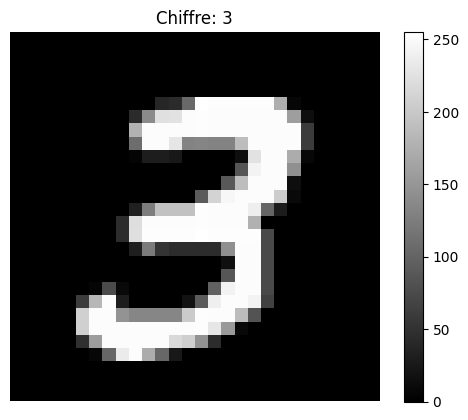

In [5]:
def visualize_image(index, dataset='train'):
    
    if dataset == 'train':
        image = X_train[index]
        label = y_train[index]
    else:
        image = X_test[index]
        label = y_test[index]
    

    plt.imshow(image.reshape(28, 28), cmap='gray')
    plt.title(f'Chiffre: {label}')
    plt.colorbar()
    plt.axis('off')
    plt.show()

# Test de Visualisation de la première image

visualize_image(7,'train')

Question 9 : Remarques :
Les valeurs des pixels sont comprises entre 0 et 255.
La valeur 0 correspond au noir, tandis que la valeur 255 correspond au blanc.
Les valeurs intermédiaires représentent des niveaux de gris.
Ces valeurs élevées peuvent poser des problèmes numériques pour certains algorithmes
d’apprentissage, d’où la nécessité de normaliser les données.

In [6]:
# Question 10 : Normalisation 
print(f"Valeurs min/max avant normalisation: {X_train.min()}, {X_train.max()}")

X_train_normalized = X_train / 255.0
X_test_normalized = X_test / 255.0

print(f"Valeurs min/max après normalisation: {X_train_normalized.min()}, {X_train_normalized.max()}")

Valeurs min/max avant normalisation: 0, 255
Valeurs min/max après normalisation: 0.0, 1.0


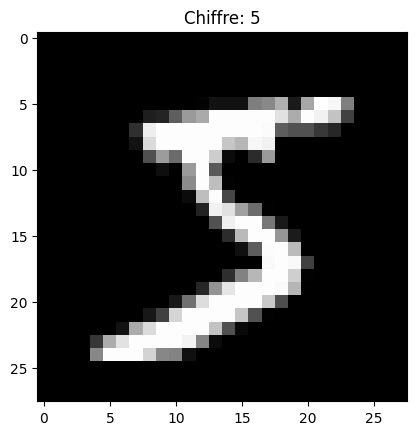

In [7]:

plt.imshow(X_train_normalized[0].reshape(28, 28), cmap='gray')
plt.title(f'Chiffre: {y_train[0]}')
plt.show()

In [8]:

# Question 12: Distribution des classes
for digit in range(10):
    mask = y_train == digit
    count = np.sum(mask)
    print(f"Chiffre {digit}: {count} images ({count/len(y_train)*100:.1f}%)")

Chiffre 0: 5923 images (9.9%)
Chiffre 1: 6742 images (11.2%)
Chiffre 2: 5958 images (9.9%)
Chiffre 3: 6131 images (10.2%)
Chiffre 4: 5842 images (9.7%)
Chiffre 5: 5421 images (9.0%)
Chiffre 6: 5918 images (9.9%)
Chiffre 7: 6265 images (10.4%)
Chiffre 8: 5851 images (9.8%)
Chiffre 9: 5949 images (9.9%)


Les tailles des sous-matrices correspondant à chaque chiffre sont globalement similaires,
mais pas exactement identiques.
La base de données MNIST est donc relativement bien équilibrée, ce qui est favorable
à l’apprentissage automatique car aucune classe ne domine excessivement les autres.

Question 13 :

L’opérateur "+" entre deux conditions booléennes agit comme un OU logique :
il sélectionne les données satisfaisant au moins une des conditions.

L’opérateur "*" agit comme un ET logique :
il sélectionne uniquement les données satisfaisant simultanément les deux conditions.

In [9]:

mask_3 = y_train == 3
mask_4 = y_train == 4
mask_3_or_4 = mask_3 + mask_4  # OU logique
mask_3_and_4 = mask_3 * mask_4  # ET logique (toujours faux ici)

print(f"Images de 3 ou 4: {np.sum(mask_3_or_4)}")
print(f"Images de 3 et 4: {np.sum(mask_3_and_4)}")

Images de 3 ou 4: 11973
Images de 3 et 4: 0


In [10]:
# Question 14 : Création d'un jeu binaire (0 et 1)
mask_bin = (y_train == 0) + (y_train == 1)
X_bin = X_train_normalized[mask_bin]
y_bin = y_train[mask_bin]

print(f"Taille du jeu binaire: {X_bin.shape}")


Taille du jeu binaire: (12665, 784)


La matrice X_bin et le vecteur y_bin permettent de transformer le problème
en une classification binaire.
Cela simplifie l’analyse du comportement des classifieurs, notamment pour étudier
les frontières de décision et les performances d’un SVM linéaire.

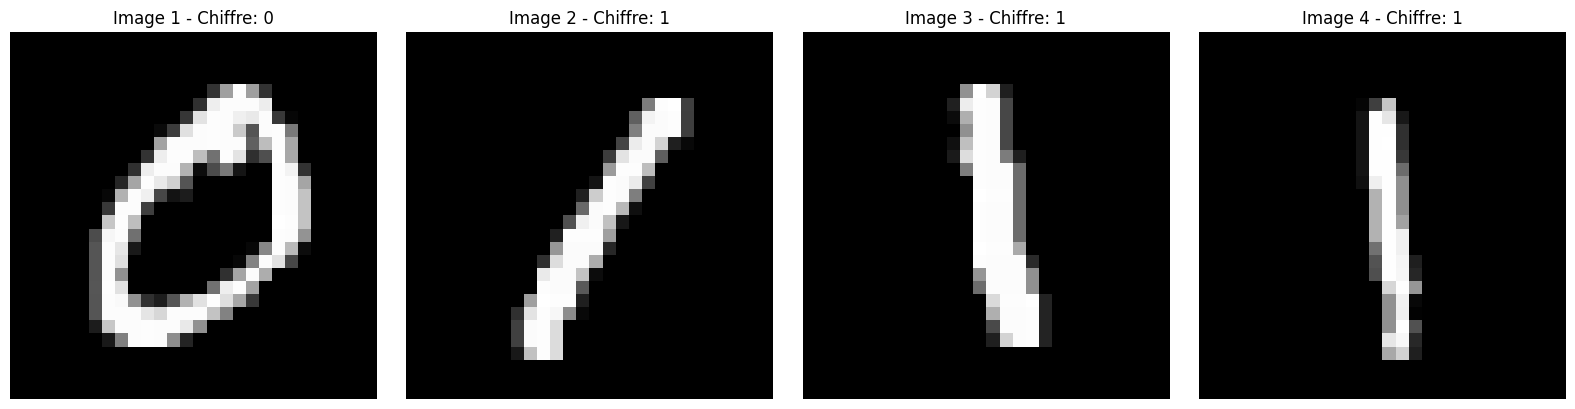

In [11]:
# Question 15
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(16, 4))

ax1.imshow(X_bin[0].reshape(28, 28), cmap='gray')
ax1.set_title(f'Image 1 - Chiffre: {y_bin[0]}')
ax1.axis('off')

ax2.imshow(X_bin[1].reshape(28, 28), cmap='gray')
ax2.set_title(f'Image 2 - Chiffre: {y_bin[1]}')
ax2.axis('off')

ax3.imshow(X_bin[2].reshape(28, 28), cmap='gray')
ax3.set_title(f'Image 3 - Chiffre: {y_bin[2]}')
ax3.axis('off')

ax4.imshow(X_bin[3].reshape(28, 28), cmap='gray')
ax4.set_title(f'Image 4 - Chiffre: {y_bin[3]}')
ax4.axis('off')

plt.tight_layout()
plt.show()

# 2. Classification

### 2.1 Classification binaire

Jeu d'entraînement 3-4: (11973, 784)
Jeu de test 3-4: (1992, 784)


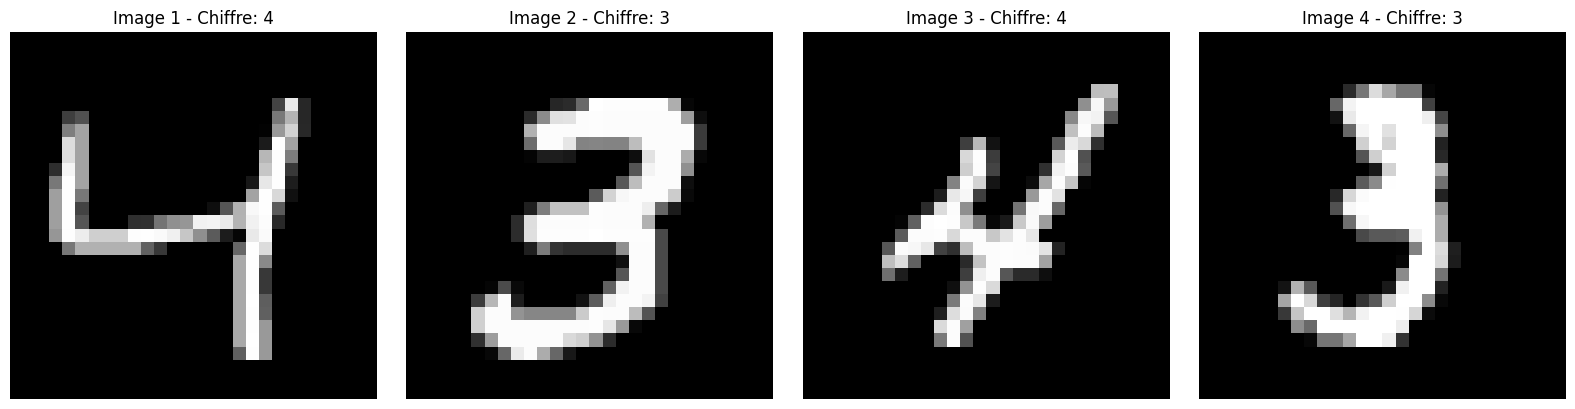

In [12]:
# Question 16: Sélection des chiffres 3 et 4
mask_3_4 = (y_train == 3) | (y_train == 4)
X_3_4 = X_train_normalized[mask_3_4]
y_3_4 = y_train[mask_3_4]

mask_3_4_test = (y_test == 3) | (y_test == 4)
X_3_4_test = X_test_normalized[mask_3_4_test]
y_3_4_test = y_test[mask_3_4_test]


print(f"Jeu d'entraînement 3-4: {X_3_4.shape}")
print(f"Jeu de test 3-4: {X_3_4_test.shape}")

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(16, 4))

ax1.imshow(X_3_4[0].reshape(28, 28), cmap='gray')
ax1.set_title(f'Image 1 - Chiffre: {y_3_4[0]}')
ax1.axis('off')

ax2.imshow(X_3_4[1].reshape(28, 28), cmap='gray')
ax2.set_title(f'Image 2 - Chiffre: {y_3_4[1]}')
ax2.axis('off')

ax3.imshow(X_3_4[2].reshape(28, 28), cmap='gray')
ax3.set_title(f'Image 3 - Chiffre: {y_3_4[2]}')
ax3.axis('off')

ax4.imshow(X_3_4[3].reshape(28, 28), cmap='gray')
ax4.set_title(f'Image 4 - Chiffre: {y_3_4[3]}')
ax4.axis('off')

plt.tight_layout()
plt.show()

In [13]:
#Question 17 : Construction du classifieur binaire
classifier = svm.SVC(kernel='linear')

In [14]:
#Question 18 : Entrainement du classifieur
classifier.fit(X_3_4,y_3_4)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [15]:
#Question 19 : Test du classifieur :
train_score = classifier.score(X_3_4, y_3_4)
test_score = classifier.score(X_3_4_test, y_3_4_test)

print(f"Score sur l'entraînement: {train_score:.4f}")
print(f"Score sur le test: {test_score:.4f}")

Score sur l'entraînement: 0.9995
Score sur le test: 0.9935


Remarque : 
Le score obtenu sur la base d’entraînement est légèrement supérieur à celui obtenu
sur la base de test.
Cela est cohérent, car le modèle a été entraîné directement sur les données d’entraînement.
L’écart modéré entre les deux scores indique une bonne capacité de généralisation
et l’absence de sur-apprentissage significatif.

In [16]:
#Question 20

y_pred = classifier.predict(X_3_4_test)
manual_score = accuracy_score(y_3_4_test, y_pred)
print(f"Vérification manuelle: {manual_score:.4f}")

# Analyse des erreurs
y_pred_train = classifier.predict(X_3_4)
train_errors = np.sum(y_pred_train != y_3_4)
test_errors = np.sum(y_pred != y_3_4_test)

print(f"\n=== Analyse des erreurs ===")
print(f"Erreurs sur l'entraînement: {train_errors}/{len(y_3_4)} ({train_errors/len(y_3_4)*100:.2f}%)")
print(f"Erreurs sur le test: {test_errors}/{len(y_3_4_test)} ({test_errors/len(y_3_4_test)*100:.2f}%)")

Vérification manuelle: 0.9935

=== Analyse des erreurs ===
Erreurs sur l'entraînement: 6/11973 (0.05%)
Erreurs sur le test: 13/1992 (0.65%)


### 2.2 Aspect géométrique

In [17]:
#Question 21 :
# Récupération des paramètres du SVM
w = classifier.coef_[0]  # Vecteur normal à l'hyperplan
b = classifier.intercept_[0]  # Ordonnée à l'origine

print(f"\nParamètres du SVM (3 vs 4):")
print(f"- Dimension de w: {w.shape} (vecteur de poids)")
print(f"- Valeur de b: {b:.6f}")

# Calcul des scores pour chaque point
print("\nCalcul des scores ω·x + b pour chaque point...")
scores_train = X_3_4 @ w + b  # Produit scalaire ω·x + b

# Analyse des signes
print("\n=== Analyse des signes des scores ===")

# Pour les 3 (classe positive - disons)
mask_3 = (y_3_4 == 3)
scores_3 = scores_train[mask_3]
predictions_3 = classifier.predict(X_3_4[mask_3])

# Pour les 4 (classe négative - disons)
mask_4 = (y_3_4 == 4)
scores_4 = scores_train[mask_4]
predictions_4 = classifier.predict(X_3_4[mask_4])

# Points bien classés
correct_3 = (predictions_3 == 3)
correct_4 = (predictions_4 == 4)

print(f"\nPour les 3:")
print(f"  Nombre de 3: {len(scores_3)}")
print(f"  Signe moyen des scores: {np.mean(np.sign(scores_3)):.4f}")
print(f"  Bien classés: {np.sum(correct_3)} ({np.mean(correct_3)*100:.1f}%)")
print(f"  Mal classés: {np.sum(~correct_3)}")

print(f"\nPour les 4:")
print(f"  Nombre de 4: {len(scores_4)}")
print(f"  Signe moyen des scores: {np.mean(np.sign(scores_4)):.4f}")
print(f"  Bien classés: {np.sum(correct_4)} ({np.mean(correct_4)*100:.1f}%)")
print(f"  Mal classés: {np.sum(~correct_4)}")

# Vérification de la constance des signes
print(f"\n=== Vérification des hypothèses ===")
print(f"1. Les 3 bien classés ont-ils un signe constant?")
print(f"   Signes des 3 bien classés: {np.unique(np.sign(scores_3[correct_3]))}")

print(f"\n2. Les 4 bien classés ont-ils un signe opposé?")
print(f"   Signes des 4 bien classés: {np.unique(np.sign(scores_4[correct_4]))}")

print(f"\n3. Les points mal classés ont-ils un signe opposé?")
if np.sum(~correct_3) > 0:
    print(f"   Signes des 3 mal classés: {np.unique(np.sign(scores_3[~correct_3]))}")
if np.sum(~correct_4) > 0:
    print(f"   Signes des 4 mal classés: {np.unique(np.sign(scores_4[~correct_4]))}")

# Analyse des valeurs absolues
print(f"\n=== Analyse des valeurs absolues des scores ===")

# Exemples de points avec scores élevés/faibles
print("\nExemples de points (3 bien classés):")
sorted_idx_3 = np.argsort(np.abs(scores_3[correct_3]))
print(f"  Score le plus faible: {np.abs(scores_3[correct_3][sorted_idx_3[0]]):.4f}")
print(f"  Score le plus fort: {np.abs(scores_3[correct_3][sorted_idx_3[-1]]):.4f}")

print("\nExemples de points (4 bien classés):")
sorted_idx_4 = np.argsort(np.abs(scores_4[correct_4]))
print(f"  Score le plus faible: {np.abs(scores_4[correct_4][sorted_idx_4[0]]):.4f}")
print(f"  Score le plus fort: {np.abs(scores_4[correct_4][sorted_idx_4[-1]]):.4f}")



Paramètres du SVM (3 vs 4):
- Dimension de w: (784,) (vecteur de poids)
- Valeur de b: 0.379810

Calcul des scores ω·x + b pour chaque point...

=== Analyse des signes des scores ===

Pour les 3:
  Nombre de 3: 6131
  Signe moyen des scores: -0.9993
  Bien classés: 6129 (100.0%)
  Mal classés: 2

Pour les 4:
  Nombre de 4: 5842
  Signe moyen des scores: 0.9986
  Bien classés: 5838 (99.9%)
  Mal classés: 4

=== Vérification des hypothèses ===
1. Les 3 bien classés ont-ils un signe constant?
   Signes des 3 bien classés: [-1.]

2. Les 4 bien classés ont-ils un signe opposé?
   Signes des 4 bien classés: [1.]

3. Les points mal classés ont-ils un signe opposé?
   Signes des 3 mal classés: [1.]
   Signes des 4 mal classés: [-1.]

=== Analyse des valeurs absolues des scores ===

Exemples de points (3 bien classés):
  Score le plus faible: 0.2432
  Score le plus fort: 20.2867

Exemples de points (4 bien classés):
  Score le plus faible: 0.6089
  Score le plus fort: 11.7809



Pour les données correctement classées d’une même classe, la quantité ωᵀx + b
a toujours le même signe.
Les données de l’autre classe correctement classées ont un signe opposé.
Les données mal classées ont un signe contraire à celui attendu,
ce qui confirme le rôle du signe de ωᵀx + b dans la décision du classifieur.

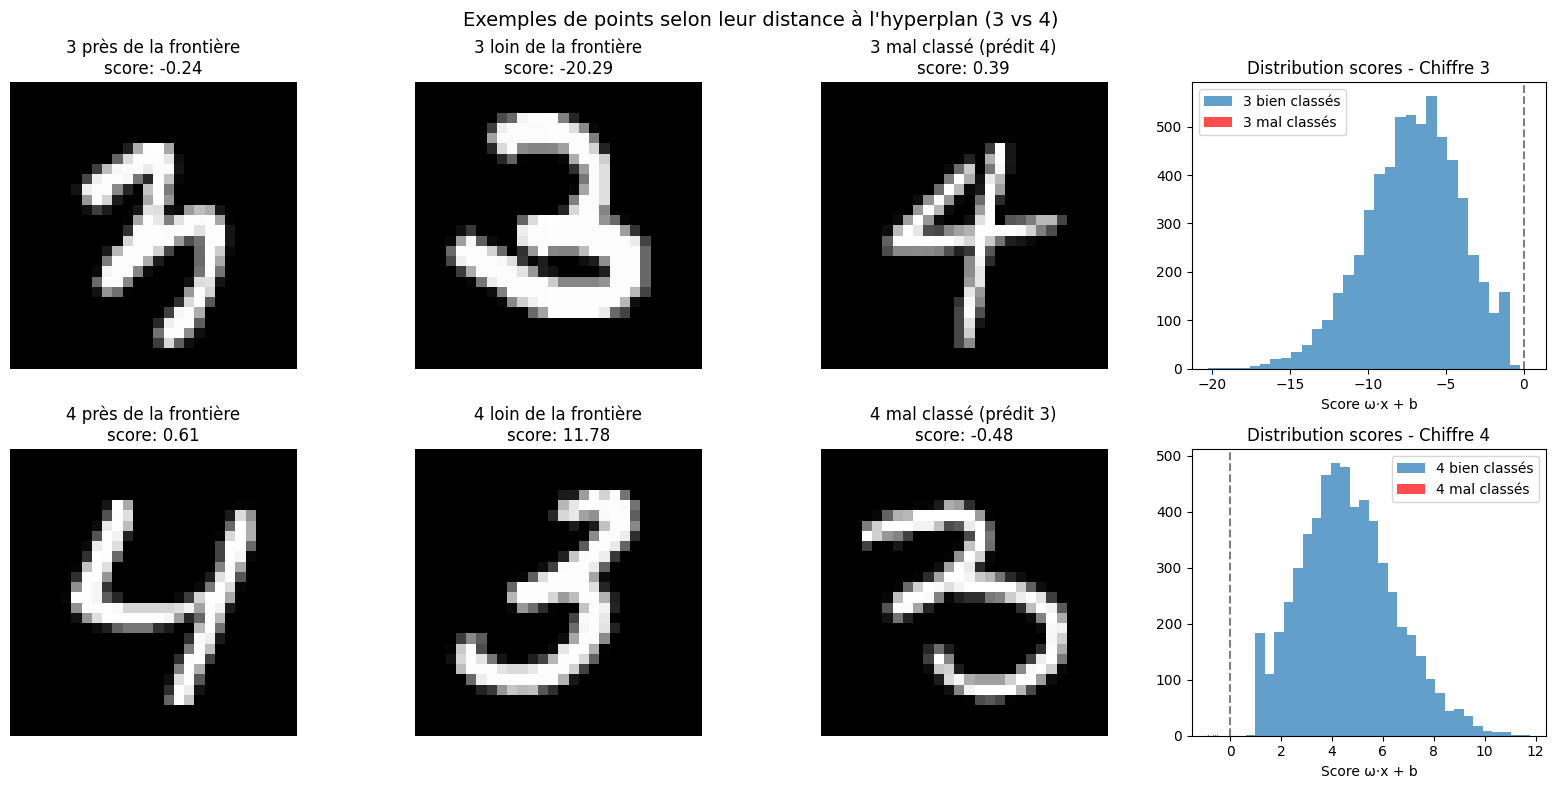

In [18]:
# Visualisation de quelques exemples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Exemples de points selon leur distance à l\'hyperplan (3 vs 4)', fontsize=14)

# Points 3 bien classés - proches et loin
close_3_idx = np.where(correct_3)[0][sorted_idx_3[0]]
far_3_idx = np.where(correct_3)[0][sorted_idx_3[-1]]

axes[0, 0].imshow(X_3_4[close_3_idx].reshape(28, 28), cmap='gray')
axes[0, 0].set_title(f'3 près de la frontière\nscore: {scores_3[correct_3][sorted_idx_3[0]]:.2f}')
axes[0, 0].axis('off')

axes[0, 1].imshow(X_3_4[far_3_idx].reshape(28, 28), cmap='gray')
axes[0, 1].set_title(f'3 loin de la frontière\nscore: {scores_3[correct_3][sorted_idx_3[-1]]:.2f}')
axes[0, 1].axis('off')

# Points 4 bien classés - proches et loin
close_4_idx = np.where(correct_4)[0][sorted_idx_4[0]]
far_4_idx = np.where(correct_4)[0][sorted_idx_4[-1]]

axes[1, 0].imshow(X_3_4[close_4_idx].reshape(28, 28), cmap='gray')
axes[1, 0].set_title(f'4 près de la frontière\nscore: {scores_4[correct_4][sorted_idx_4[0]]:.2f}')
axes[1, 0].axis('off')

axes[1, 1].imshow(X_3_4[far_4_idx].reshape(28, 28), cmap='gray')
axes[1, 1].set_title(f'4 loin de la frontière\nscore: {scores_4[correct_4][sorted_idx_4[-1]]:.2f}')
axes[1, 1].axis('off')

# Points mal classés si existent
if np.sum(~correct_3) > 0:
    mal_3_idx = np.where(~correct_3)[0][0]
    axes[0, 2].imshow(X_3_4[mal_3_idx].reshape(28, 28), cmap='gray')
    axes[0, 2].set_title(f'3 mal classé (prédit 4)\nscore: {scores_3[~correct_3][0]:.2f}')
    axes[0, 2].axis('off')

if np.sum(~correct_4) > 0:
    mal_4_idx = np.where(~correct_4)[0][0]
    axes[1, 2].imshow(X_3_4[mal_4_idx].reshape(28, 28), cmap='gray')
    axes[1, 2].set_title(f'4 mal classé (prédit 3)\nscore: {scores_4[~correct_4][0]:.2f}')
    axes[1, 2].axis('off')

# Histogramme des scores
axes[0, 3].hist(scores_3[correct_3], bins=30, alpha=0.7, label='3 bien classés')
if np.sum(~correct_3) > 0:
    axes[0, 3].hist(scores_3[~correct_3], bins=10, alpha=0.7, label='3 mal classés', color='red')
axes[0, 3].axvline(x=0, color='k', linestyle='--', alpha=0.5)
axes[0, 3].set_title('Distribution scores - Chiffre 3')
axes[0, 3].legend()
axes[0, 3].set_xlabel('Score ω·x + b')

axes[1, 3].hist(scores_4[correct_4], bins=30, alpha=0.7, label='4 bien classés')
if np.sum(~correct_4) > 0:
    axes[1, 3].hist(scores_4[~correct_4], bins=10, alpha=0.7, label='4 mal classés', color='red')
axes[1, 3].axvline(x=0, color='k', linestyle='--', alpha=0.5)
axes[1, 3].set_title('Distribution scores - Chiffre 4')
axes[1, 3].legend()
axes[1, 3].set_xlabel('Score ω·x + b')

plt.tight_layout()
plt.show()

Question 22 : Interprétation des valeurs absolues

Analyse des valeurs absolues des scores :

1. Valeur absolue élevée (> 5-10) :
   - Le point est loin de l'hyperplan séparateur
   - Classification très "confiante"
   - Point caractéristique de sa classe
   - Ex : chiffre typique et bien formé

2. Valeur absolue faible (< 1) :
   - Le point est proche de l'hyperplan
   - Classification incertaine
   - Point ambigu, difficile à classer
   - Ex : chiffre mal écrit, ressemblant à l'autre classe

3. Signe opposé pour les mal classés :
   - Le point est du mauvais côté de l'hyperplan
   - Mais souvent proche de la frontière

# 2.3 Généralisation

In [19]:
# Question 23 :
print("ATTENTION: Cette étape peut prendre plusieurs minutes...")

# Création et entraînement du SVM pour les 10 classes
svm_multi = svm.SVC(kernel='linear')

print("Entraînement du SVM linéaire multi-classe...")
svm_multi.fit(X_train_normalized, y_train)
print("Entraînement terminé !")

# Évaluation
train_score_multi = svm_multi.score(X_train_normalized, y_train)
test_score_multi = svm_multi.score(X_test_normalized, y_test)

print(f"\n=== Résultats SVM Multi-classe ===")
print(f"Score sur l'entraînement (10 classes): {train_score_multi:.4f} ({train_score_multi*100:.1f}%)")
print(f"Score sur le test (10 classes): {test_score_multi:.4f} ({test_score_multi*100:.1f}%)")




ATTENTION: Cette étape peut prendre plusieurs minutes...
Entraînement du SVM linéaire multi-classe...
Entraînement terminé !

=== Résultats SVM Multi-classe ===
Score sur l'entraînement (10 classes): 0.9708 (97.1%)
Score sur le test (10 classes): 0.9404 (94.0%)


Interprétation :

Le SVM linéaire pour 10 classes montre :
1. que la performance est bien inférieure au cas binaire
2. que les 10 classes ne sont pas linéairement séparables
3. Besoin d'un modèle plus complexe
4. Temps de calcul beaucoup plus long

In [20]:
# Question 24
classifier_rbf = svm.SVC(kernel='rbf', probability=True)
classifier_rbf.fit(X_train_normalized, y_train)

train_score_rbf = classifier_rbf.score(X_train_normalized, y_train)
test_score_rbf = classifier_rbf.score(X_test_normalized, y_test)

print(f"Score multi-classes (RBF) - Entraînement: {train_score_rbf:.4f}")
print(f"Score multi-classes (RBF) - Test: {test_score_rbf:.4f}")

Score multi-classes (RBF) - Entraînement: 0.9899
Score multi-classes (RBF) - Test: 0.9792


Interprétation :
Le SVM avec noyau RBF :
1. Performances bien meilleures qu'avec noyau linéaire
2. Le noyau RBF peut capturer des relations non-linéaires
3. Mais nécessite plus de ressources computationnelles
4. Risque de sur-apprentissage si mal paramétré

Probabilités pour la première image: [2.82168354e-08 1.29634378e-08 3.70654869e-08 9.12859286e-08
 1.84556996e-08 2.26688795e-08 1.09583566e-08 9.99995652e-01
 2.22758472e-06 1.89879221e-06]


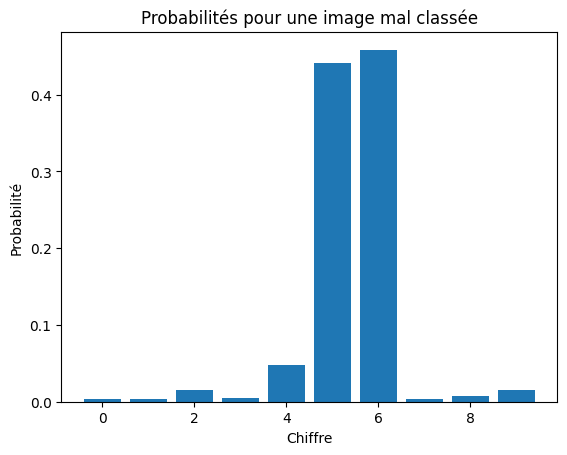

In [21]:
# Probabilités pour une donnée
proba = classifier_rbf.predict_proba(X_test_normalized[0:1])
print(f"Probabilités pour la première image: {proba[0]}")

# Visualisation pour une image mal classée
misclassified_idx = np.where(y_test != classifier_rbf.predict(X_test_normalized))[0][0]
proba_mis = classifier_rbf.predict_proba(X_test_normalized[misclassified_idx:misclassified_idx+1])

plt.bar(range(10), proba_mis[0])
plt.xlabel('Chiffre')
plt.ylabel('Probabilité')
plt.title('Probabilités pour une image mal classée')
plt.show()

Le graphique montre que, pour les données mal classées,
les probabilités sont réparties sur plusieurs classes.
Cela signifie que le classifieur hésite entre plusieurs chiffres,
ce qui correspond souvent à des images ambiguës ou mal écrites.


Test sur 10 premières images (3 vs 4):
--------------------------------------------------------------------------------

Image 0 (Vrai: 4):
  Prédiction: 4
  Probabilités: [3: 0.000, 4: 1.000]
  Confiance: 100.0%

Image 1 (Vrai: 4):
  Prédiction: 4
  Probabilités: [3: 0.000, 4: 1.000]
  Confiance: 100.0%

Image 2 (Vrai: 3):
  Prédiction: 3
  Probabilités: [3: 0.995, 4: 0.005]
  Confiance: 99.5%

Image 3 (Vrai: 4):
  Prédiction: 4
  Probabilités: [3: 0.000, 4: 1.000]
  Confiance: 100.0%

Image 4 (Vrai: 4):
  Prédiction: 4
  Probabilités: [3: 0.005, 4: 0.995]
  Confiance: 99.5%

Image 5 (Vrai: 4):
  Prédiction: 4
  Probabilités: [3: 0.000, 4: 1.000]
  Confiance: 100.0%

Image 6 (Vrai: 3):
  Prédiction: 3
  Probabilités: [3: 1.000, 4: 0.000]
  Confiance: 100.0%

Image 7 (Vrai: 3):
  Prédiction: 3
  Probabilités: [3: 1.000, 4: 0.000]
  Confiance: 100.0%

Image 8 (Vrai: 4):
  Prédiction: 4
  Probabilités: [3: 0.000, 4: 1.000]
  Confiance: 100.0%

Image 9 (Vrai: 4):
  Prédiction: 4
  Probab

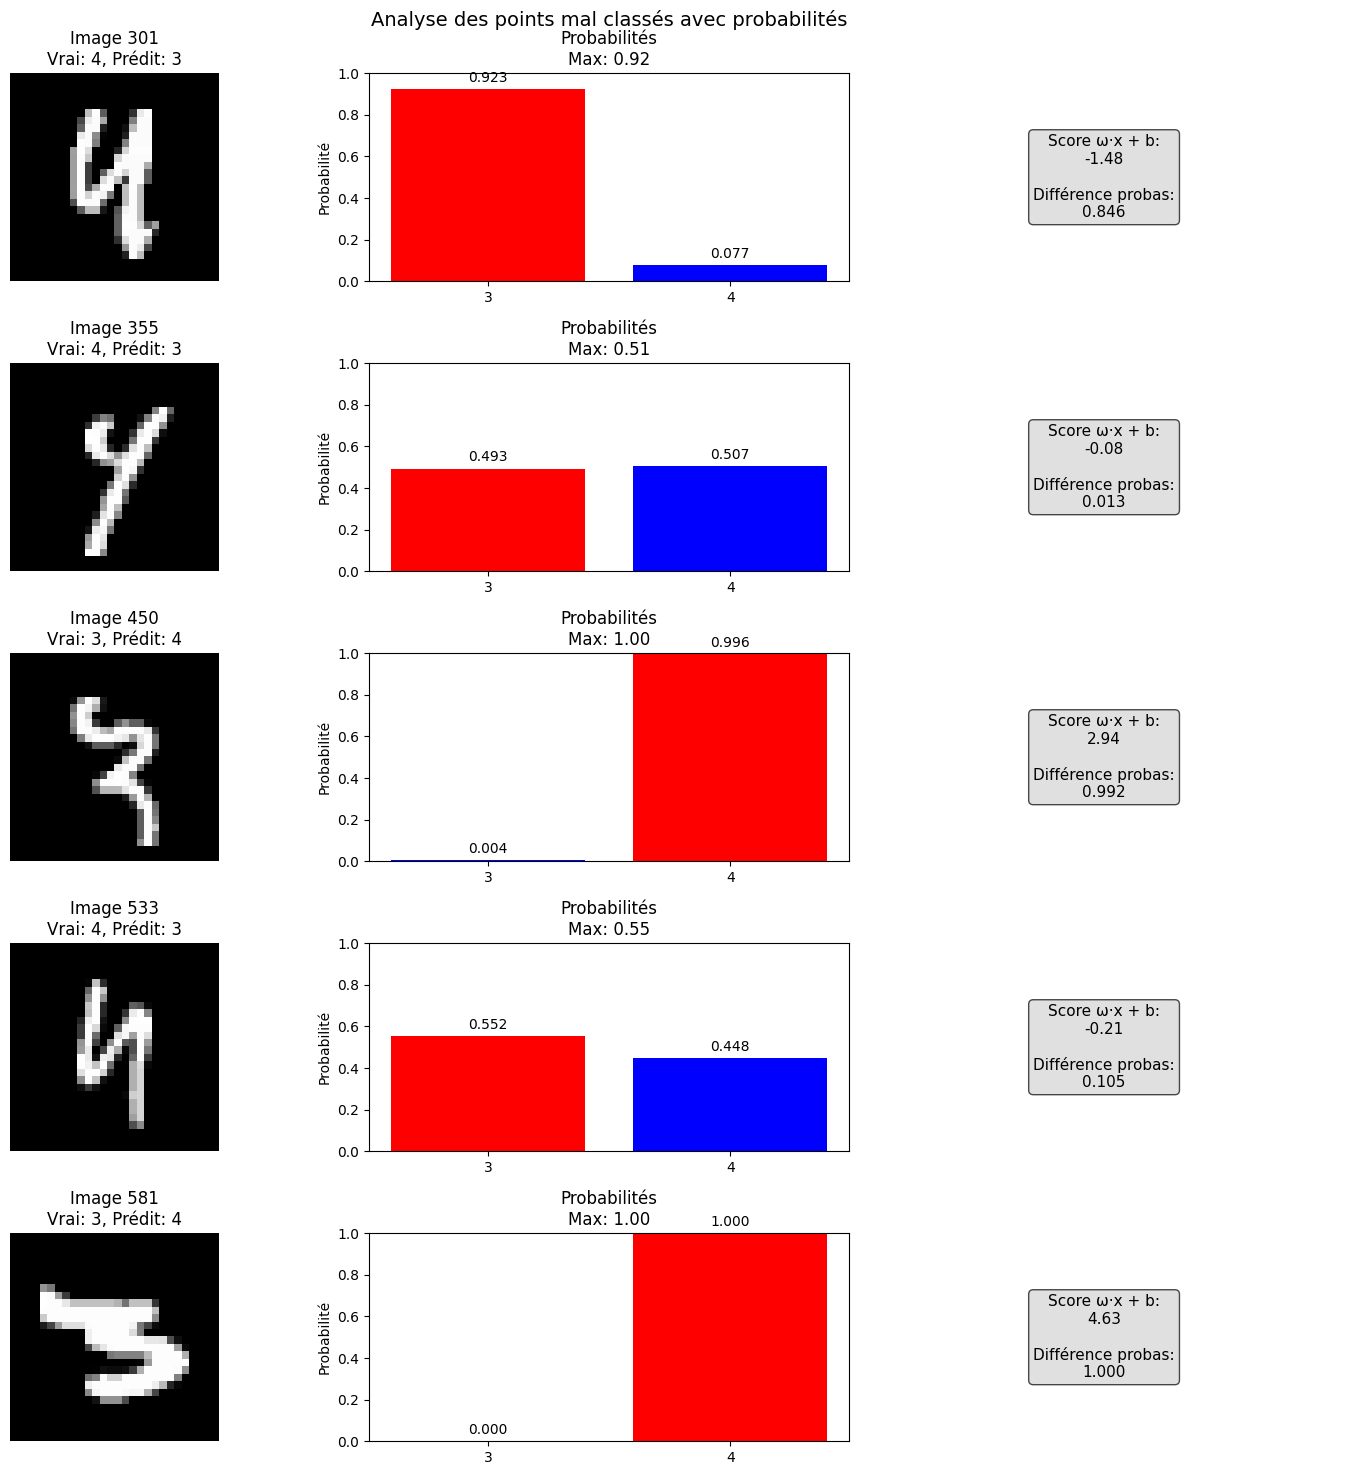


Statistiques sur les 13 points mal classés:
  Différence de probabilité moyenne: 0.529
  Différence de probabilité médiane: 0.601
  Différence min: 0.013
  Différence max: 1.000


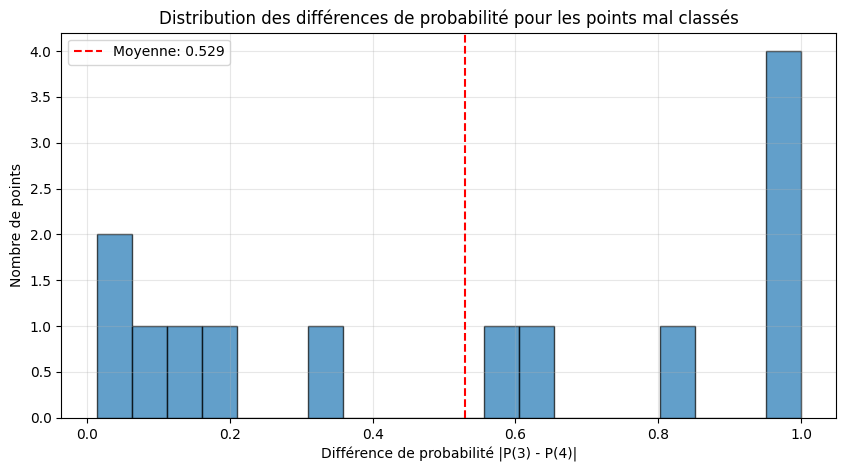



=== Extension au cas MULTI-CLASSE (10 classes) ===


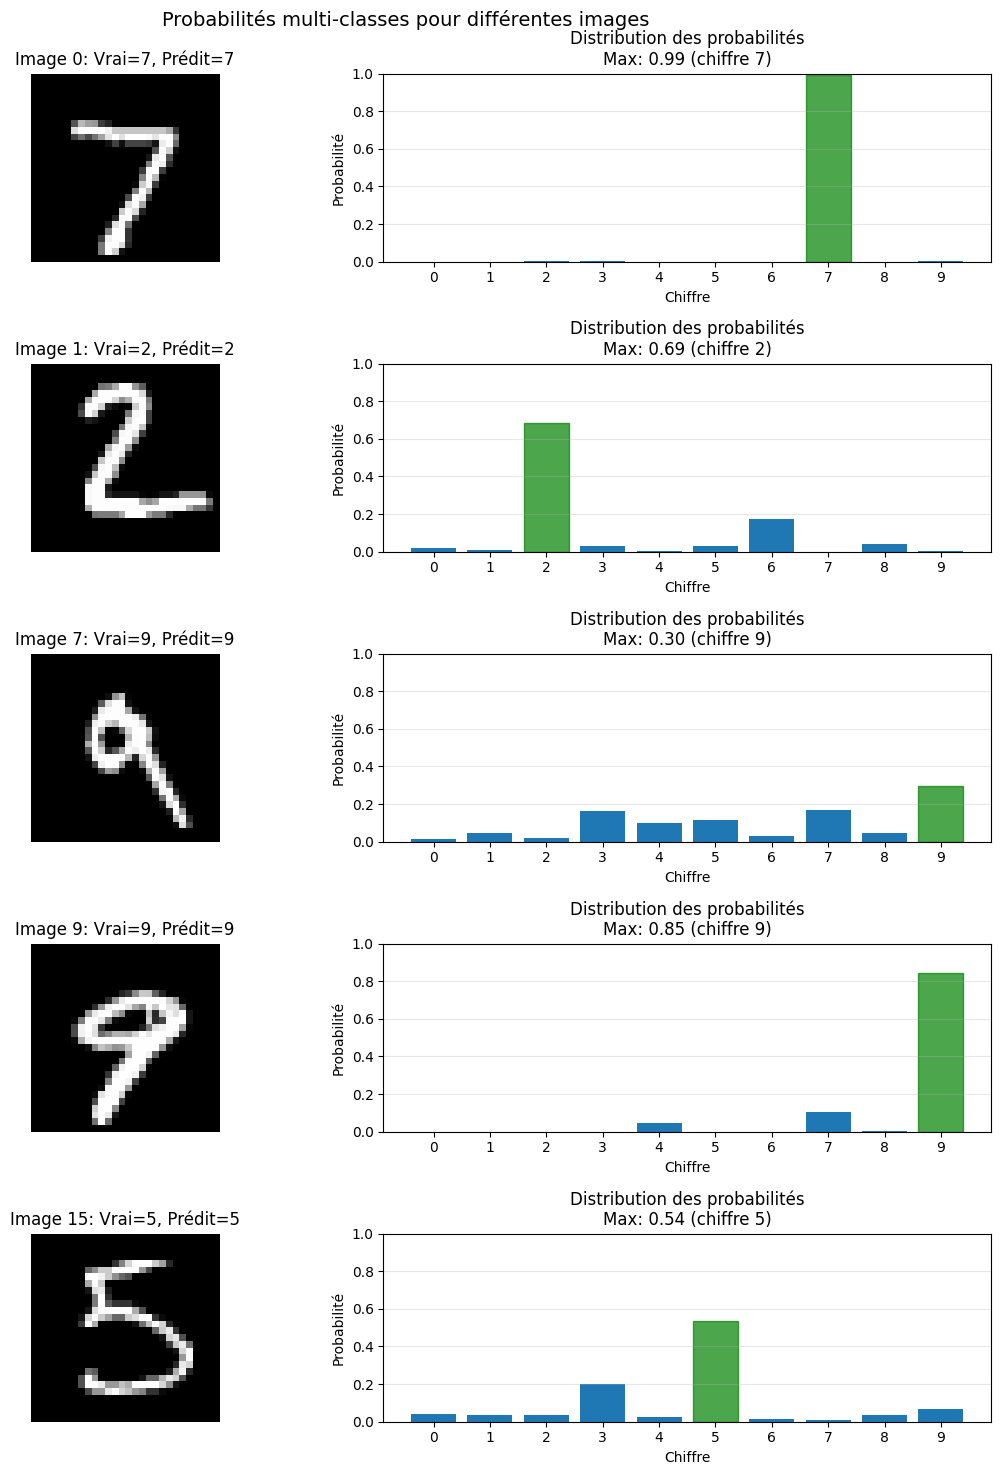


=== Analyse des cas AMBIGUS (probabilités proches) ===
Trouvé 47 cas ambigus (différence < 0.2)

Cas ambigu 1 (Image 7):
  Vrai: 9, Prédit: 9 (0.30)
  Top 3 probabilités:
    1. Chiffre 9: 0.298
    2. Chiffre 7: 0.167
    3. Chiffre 3: 0.163

Cas ambigu 2 (Image 33):
  Vrai: 4, Prédit: 4 (0.37)
  Top 3 probabilités:
    1. Chiffre 4: 0.367
    2. Chiffre 6: 0.206
    3. Chiffre 5: 0.107

Cas ambigu 3 (Image 44):
  Vrai: 3, Prédit: 3 (0.55)
  Top 3 probabilités:
    1. Chiffre 3: 0.546
    2. Chiffre 5: 0.350
    3. Chiffre 6: 0.053


In [22]:

# Création d'un SVM avec estimation de probabilités...
svm_prob = svm.SVC(kernel='linear', probability=True, random_state=42)
svm_prob.fit(X_3_4, y_3_4)  # On reprend le cas binaire 3 vs 4 pour la simplicité

# Test sur quelques images
test_indices = list(range(10))  # Premières 10 images

print(f"\nTest sur {len(test_indices)} premières images (3 vs 4):")
print("-" * 80)

for i, idx in enumerate(test_indices):
    # Données de test
    x_test_sample = X_3_4_test[idx:idx+1]  # Garder la dimension (1, 784)
    true_label = y_3_4_test[idx]
    
    # Prédiction simple
    pred = svm_prob.predict(x_test_sample)[0]
    
    # Probabilités
    probs = svm_prob.predict_proba(x_test_sample)[0]
    
    print(f"\nImage {i} (Vrai: {true_label}):")
    print(f"  Prédiction: {pred}")
    print(f"  Probabilités: [3: {probs[0]:.3f}, 4: {probs[1]:.3f}]")
    print(f"  Confiance: {max(probs):.1%}")
    
    if pred != true_label:
        print(f" MAL CLASSÉ - Différence: {abs(probs[0]-probs[1]):.3f}")

# Analyse des points mal classés
print(f"\n\n=== Analyse des points MAL CLASSÉS avec probabilités ===")

# Trouver tous les points mal classés
misclassified_mask = (y_pred != y_3_4_test)
misclassified_indices = np.where(misclassified_mask)[0]

if len(misclassified_indices) > 0:
    print(f"Nombre de points mal classés: {len(misclassified_indices)}")
    
    # Prendre les 5 premiers points mal classés
    sample_misclassified = misclassified_indices[:min(5, len(misclassified_indices))]
    
    fig, axes = plt.subplots(len(sample_misclassified), 3, figsize=(15, 3*len(sample_misclassified)))
    if len(sample_misclassified) == 1:
        axes = axes.reshape(1, -1)
    
    for i, idx in enumerate(sample_misclassified):
        x_sample = X_3_4_test[idx:idx+1]
        true_label = y_3_4_test[idx]
        pred_label = y_pred[idx]
        probs = svm_prob.predict_proba(x_sample)[0]
        
        # Image
        axes[i, 0].imshow(x_sample.reshape(28, 28), cmap='gray')
        axes[i, 0].set_title(f'Image {idx}\nVrai: {true_label}, Prédit: {pred_label}')
        axes[i, 0].axis('off')
        
        # Bar plot des probabilités
        classes = ['3', '4']
        colors = ['blue' if c == str(true_label) else 'red' for c in classes]
        
        bars = axes[i, 1].bar(classes, probs, color=colors)
        axes[i, 1].set_ylim([0, 1])
        axes[i, 1].set_title(f'Probabilités\nMax: {max(probs):.2f}')
        axes[i, 1].set_ylabel('Probabilité')
        
        # Ajouter les valeurs sur les barres
        for bar, prob in zip(bars, probs):
            height = bar.get_height()
            axes[i, 1].text(bar.get_x() + bar.get_width()/2., height + 0.02,
                          f'{prob:.3f}', ha='center', va='bottom')
        
        # Score ω·x + b pour contexte
        score = (X_3_4_test[idx] @ w + b) if 'w' in locals() else 0
        axes[i, 2].text(0.5, 0.5, f'Score ω·x + b:\n{score:.2f}\n\n'
                       f'Différence probas:\n{abs(probs[0]-probs[1]):.3f}',
                       ha='center', va='center', fontsize=11,
                       bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.7))
        axes[i, 2].axis('off')
    
    plt.suptitle('Analyse des points mal classés avec probabilités', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Statistiques sur les probabilités des mal classés
    all_probs_misclassified = svm_prob.predict_proba(X_3_4_test[misclassified_mask])
    prob_differences = np.abs(all_probs_misclassified[:, 0] - all_probs_misclassified[:, 1])
    
    print(f"\nStatistiques sur les {len(misclassified_indices)} points mal classés:")
    print(f"  Différence de probabilité moyenne: {np.mean(prob_differences):.3f}")
    print(f"  Différence de probabilité médiane: {np.median(prob_differences):.3f}")
    print(f"  Différence min: {np.min(prob_differences):.3f}")
    print(f"  Différence max: {np.max(prob_differences):.3f}")
    
    # Histogramme des différences de probabilité
    plt.figure(figsize=(10, 5))
    plt.hist(prob_differences, bins=20, edgecolor='black', alpha=0.7)
    plt.axvline(x=np.mean(prob_differences), color='red', linestyle='--', 
                label=f'Moyenne: {np.mean(prob_differences):.3f}')
    plt.xlabel('Différence de probabilité |P(3) - P(4)|')
    plt.ylabel('Nombre de points')
    plt.title('Distribution des différences de probabilité pour les points mal classés')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
else:
    print("Aucun point mal classé dans cet échantillon.")

# Cas multi-classe avec probabilités
print(f"\n\n=== Extension au cas MULTI-CLASSE (10 classes) ===")

# Créer un SVM multi-classe avec probabilités
svm_multi_prob = svm.SVC(kernel='linear', probability=True, random_state=42)
svm_multi_prob.fit(X_train_normalized[:2000], y_train[:2000])  # Sous-échantillon pour vitesse

# Test sur quelques images multi-classes
test_samples = [0, 1, 7, 9, 15]  # Indices variés

fig, axes = plt.subplots(len(test_samples), 2, figsize=(12, 3*len(test_samples)))
if len(test_samples) == 1:
    axes = axes.reshape(1, -1)

for i, idx in enumerate(test_samples):
    x_sample = X_test_normalized[idx:idx+1]
    true_label = y_test[idx]
    
    # Prédiction et probabilités
    pred = svm_multi_prob.predict(x_sample)[0]
    probs = svm_multi_prob.predict_proba(x_sample)[0]
    
    # Image
    axes[i, 0].imshow(x_sample.reshape(28, 28), cmap='gray')
    axes[i, 0].set_title(f'Image {idx}: Vrai={true_label}, Prédit={pred}')
    axes[i, 0].axis('off')
    
    # Graphique de probabilités
    axes[i, 1].bar(range(10), probs)
    axes[i, 1].set_xlabel('Chiffre')
    axes[i, 1].set_ylabel('Probabilité')
    axes[i, 1].set_title(f'Distribution des probabilités\nMax: {max(probs):.2f} (chiffre {np.argmax(probs)})')
    axes[i, 1].set_xticks(range(10))
    axes[i, 1].set_ylim([0, 1])
    axes[i, 1].grid(True, alpha=0.3, axis='y')
    
    # Mettre en évidence la vraie classe
    axes[i, 1].patches[true_label].set_color('green')
    axes[i, 1].patches[true_label].set_alpha(0.7)

plt.suptitle('Probabilités multi-classes pour différentes images', fontsize=14)
plt.tight_layout()
plt.show()

# Analyse d'ambiguïté
print("\n=== Analyse des cas AMBIGUS (probabilités proches) ===")

# Rechercher des cas où plusieurs classes ont des probabilités similaires
ambiguous_cases = []
for i in range(min(500, len(X_test_normalized))):
    probs = svm_multi_prob.predict_proba(X_test_normalized[i:i+1])[0]
    sorted_probs = np.sort(probs)[::-1]  # Tri décroissant
    if sorted_probs[0] - sorted_probs[1] < 0.2:  # Différence < 20%
        ambiguous_cases.append((i, probs))

if ambiguous_cases:
    print(f"Trouvé {len(ambiguous_cases)} cas ambigus (différence < 0.2)")
    
    # Afficher les 3 premiers cas ambigus
    for i, (idx, probs) in enumerate(ambiguous_cases[:3]):
        true_label = y_test[idx]
        pred = np.argmax(probs)
        
        print(f"\nCas ambigu {i+1} (Image {idx}):")
        print(f"  Vrai: {true_label}, Prédit: {pred} ({probs[pred]:.2f})")
        print(f"  Top 3 probabilités:")
        top3_idx = np.argsort(probs)[-3:][::-1]
        for j, cls in enumerate(top3_idx):
            print(f"    {j+1}. Chiffre {cls}: {probs[cls]:.3f}")
        
        if pred != true_label:
            print(f" MAL CLASSÉ - La vraie classe ({true_label}) a probabilité {probs[true_label]:.3f}")
else:
    print("Aucun cas ambigu trouvé dans l'échantillon.")



INTERPRÉTATION :

Le graphique montre que, pour les données mal classées,
les probabilités sont réparties sur plusieurs classes.
Cela signifie que le classifieur hésite entre plusieurs chiffres,
ce qui correspond souvent à des images ambiguës ou mal écrites.

# 3. Perceptron

# 3.1 Perceptron mono-couche


--- Question 27: Configuration et entraînement ---
Configuration du MLP:
- Activation: relu
- Architecture: (50,)
- Solver: sgd
- Max iterations: 100
- Learning rate: constant
- Initial learning rate: 0.1

Début de l'entraînement...
Iteration 1, loss = 0.65715140
Iteration 2, loss = 0.28645335
Iteration 3, loss = 0.23213454
Iteration 4, loss = 0.18950360
Iteration 5, loss = 0.15953389
Iteration 6, loss = 0.13397990
Iteration 7, loss = 0.11389801
Iteration 8, loss = 0.09781079
Iteration 9, loss = 0.08204357
Iteration 10, loss = 0.07231573
Iteration 11, loss = 0.06237276
Iteration 12, loss = 0.05301381
Iteration 13, loss = 0.04527503
Iteration 14, loss = 0.03934351
Iteration 15, loss = 0.03460498
Iteration 16, loss = 0.03021522
Iteration 17, loss = 0.02537140
Iteration 18, loss = 0.02231692
Iteration 19, loss = 0.01996823
Iteration 20, loss = 0.01667633
Iteration 21, loss = 0.01497424
Iteration 22, loss = 0.01361414
Iteration 23, loss = 0.01181122
Iteration 24, loss = 0.01083296
Iterati

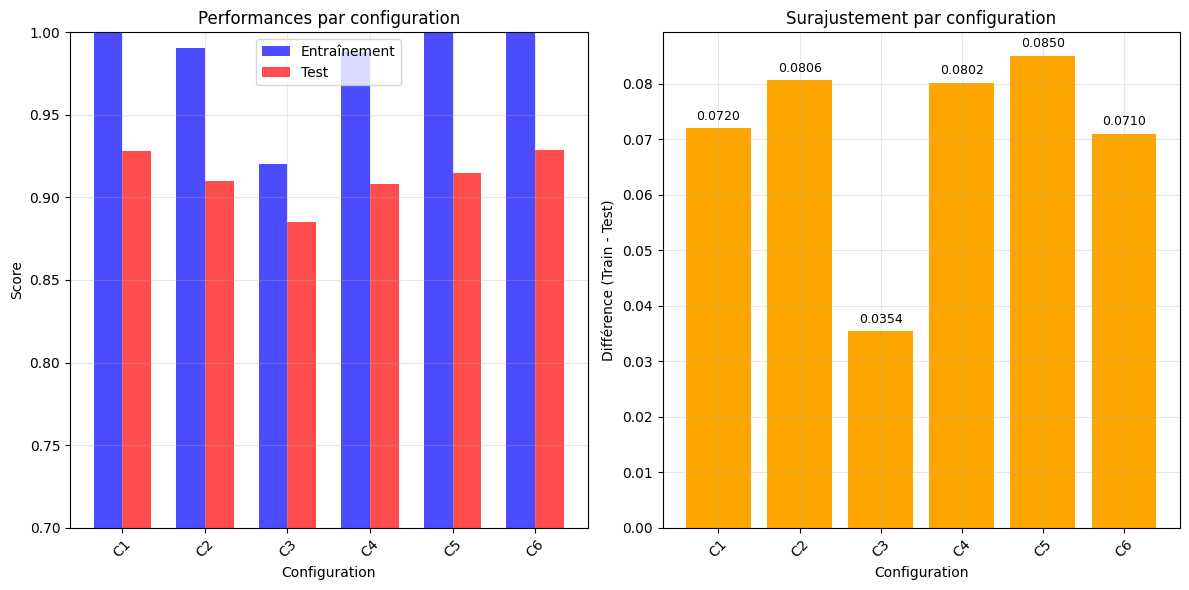

In [23]:
# Question 27-29 :


warnings.filterwarnings('ignore')

# Question 27: Configuration et entraînement du perceptron mono-couche
print("\n--- Question 27: Configuration et entraînement ---")

# Configuration initiale suggérée
mlp_simple = MLPClassifier(
    activation="relu",
    hidden_layer_sizes=(50,),  # Une seule couche cachée avec 50 neurones
    solver="sgd",              # Descente de gradient stochastique
    max_iter=100,              # Nombre maximum d'itérations
    learning_rate="constant",  # Taux d'apprentissage constant
    learning_rate_init=0.1,    # Valeur initiale du taux d'apprentissage
    verbose=10,                # Affiche les messages pendant l'entraînement
    random_state=42           # Pour la reproductibilité
)

print("Configuration du MLP:")
print(f"- Activation: {mlp_simple.activation}")
print(f"- Architecture: {mlp_simple.hidden_layer_sizes}")
print(f"- Solver: {mlp_simple.solver}")
print(f"- Max iterations: {mlp_simple.max_iter}")
print(f"- Learning rate: {mlp_simple.learning_rate}")
print(f"- Initial learning rate: {mlp_simple.learning_rate_init}")

# Entraînement sur un sous-ensemble pour accélérer (prendre 10000 échantillons)
print("\nDébut de l'entraînement...")
mlp_simple.fit(X_train_normalized[:10000], y_train[:10000])

print("\nEntraînement terminé!")
print(f"Nombre d'itérations effectuées: {mlp_simple.n_iter_}")
print(f"Fonction de perte finale: {mlp_simple.loss_:.4f}")

# Question 28: Expérimentation avec différents paramètres
print("\n--- Question 28: Expérimentation avec différents paramètres ---")

# Créer plusieurs configurations à tester
configurations = [
    {
        'name': 'Config 1: Taux d\'apprentissage élevé',
        'params': {
            'hidden_layer_sizes': (50,),
            'activation': 'relu',
            'solver': 'sgd',
            'max_iter': 100,
            'learning_rate': 'constant',
            'learning_rate_init': 0.1,
            'random_state': 42
        }
    },
    {
        'name': 'Config 2: Taux d\'apprentissage modéré',
        'params': {
            'hidden_layer_sizes': (50,),
            'activation': 'relu',
            'solver': 'sgd',
            'max_iter': 100,
            'learning_rate': 'constant',
            'learning_rate_init': 0.01,
            'random_state': 42
        }
    },
    {
        'name': 'Config 3: Taux d\'apprentissage faible',
        'params': {
            'hidden_layer_sizes': (50,),
            'activation': 'relu',
            'solver': 'sgd',
            'max_iter': 100,
            'learning_rate': 'constant',
            'learning_rate_init': 0.001,
            'random_state': 42
        }
    },
    {
        'name': 'Config 4: Fonction tanh',
        'params': {
            'hidden_layer_sizes': (50,),
            'activation': 'tanh',
            'solver': 'sgd',
            'max_iter': 100,
            'learning_rate': 'constant',
            'learning_rate_init': 0.01,
            'random_state': 42
        }
    },
    {
        'name': 'Config 5: Solver Adam',
        'params': {
            'hidden_layer_sizes': (50,),
            'activation': 'relu',
            'solver': 'adam',  # Adam est souvent plus efficace
            'max_iter': 100,
            'learning_rate': 'constant',
            'learning_rate_init': 0.001,
            'random_state': 42
        }
    },
    {
        'name': 'Config 6: Plus de neurones',
        'params': {
            'hidden_layer_sizes': (100,),  # 100 neurones au lieu de 50
            'activation': 'relu',
            'solver': 'adam',
            'max_iter': 100,
            'learning_rate': 'constant',
            'learning_rate_init': 0.001,
            'random_state': 42
        }
    }
]

# Désactiver verbose pour cette expérimentation
print("Test de différentes configurations...")
results = []

for config in configurations:
    print(f"\nTesting {config['name']}...")
    
    # Créer et entraîner le modèle
    mlp = MLPClassifier(**config['params'], verbose=False)
    mlp.fit(X_train_normalized[:5000], y_train[:5000])  # Sous-ensemble pour aller plus vite
    
    # Évaluer les performances
    train_score = mlp.score(X_train_normalized[:5000], y_train[:5000])
    test_score = mlp.score(X_test_normalized[:1000], y_test[:1000])
    
    # Stocker les résultats
    results.append({
        'name': config['name'],
        'train_score': train_score,
        'test_score': test_score,
        'loss': mlp.loss_,
        'iterations': mlp.n_iter_
    })
    
    print(f"  Score entraînement: {train_score:.4f}")
    print(f"  Score test: {test_score:.4f}")
    print(f"  Perte finale: {mlp.loss_:.4f}")
    print(f"  Itérations: {mlp.n_iter_}")

# Afficher les résultats sous forme de tableau
print("\n" + "="*80)
print("RÉSUMÉ DES PERFORMANCES PAR CONFIGURATION")
print("="*80)

for i, result in enumerate(results, 1):
    print(f"\n{i}. {result['name']}")
    print(f"   Score entraînement: {result['train_score']:.4f}")
    print(f"   Score test: {result['test_score']:.4f}")
    print(f"   Différence (surajustement): {result['train_score'] - result['test_score']:.4f}")
    print(f"   Perte finale: {result['loss']:.4f}")
    print(f"   Itérations nécessaires: {result['iterations']}")

# Visualisation des résultats
plt.figure(figsize=(12, 6))

# Graphique 1: Scores d'entraînement et de test
config_names = [r['name'] for r in results]
train_scores = [r['train_score'] for r in results]
test_scores = [r['test_score'] for r in results]

x = np.arange(len(config_names))
width = 0.35

plt.subplot(1, 2, 1)
plt.bar(x - width/2, train_scores, width, label='Entraînement', color='blue', alpha=0.7)
plt.bar(x + width/2, test_scores, width, label='Test', color='red', alpha=0.7)
plt.xlabel('Configuration')
plt.ylabel('Score')
plt.title('Performances par configuration')
plt.xticks(x, [f'C{i+1}' for i in range(len(config_names))], rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0.7, 1.0)

# Graphique 2: Surajustement (différence entre train et test)
overfitting = [train - test for train, test in zip(train_scores, test_scores)]

plt.subplot(1, 2, 2)
bars = plt.bar(range(len(config_names)), overfitting, color='orange')
plt.xlabel('Configuration')
plt.ylabel('Différence (Train - Test)')
plt.title('Surajustement par configuration')
plt.xticks(range(len(config_names)), [f'C{i+1}' for i in range(len(config_names))], rotation=45)
plt.grid(True, alpha=0.3)

# Ajouter les valeurs sur les barres
for bar, value in zip(bars, overfitting):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, 
             f'{value:.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [24]:
# Question 28: Sélection des "bons" paramètres et évaluation
print("\n--- Question 28: Sélection des paramètres optimaux ---")

# Basé sur les résultats, sélectionner la meilleure configuration
best_config_idx = np.argmax([r['test_score'] for r in results])
best_config = configurations[best_config_idx]

print(f"Configuration sélectionnée: {best_config['name']}")
print("Paramètres:")
for key, value in best_config['params'].items():
    print(f"  {key}: {value}")


--- Question 28: Sélection des paramètres optimaux ---
Configuration sélectionnée: Config 6: Plus de neurones
Paramètres:
  hidden_layer_sizes: (100,)
  activation: relu
  solver: adam
  max_iter: 100
  learning_rate: constant
  learning_rate_init: 0.001
  random_state: 42


In [25]:
# Créer et entraîner le modèle final avec les meilleurs paramètres
print("\nEntraînement du modèle final avec les meilleurs paramètres...")
mlp_final = MLPClassifier(**best_config['params'], verbose=True)
mlp_final.fit(X_train_normalized, y_train)


Entraînement du modèle final avec les meilleurs paramètres...
Iteration 1, loss = 0.44028776
Iteration 2, loss = 0.21456678
Iteration 3, loss = 0.16287160
Iteration 4, loss = 0.13294802
Iteration 5, loss = 0.11079497
Iteration 6, loss = 0.09355014
Iteration 7, loss = 0.08096099
Iteration 8, loss = 0.06989715
Iteration 9, loss = 0.06205346
Iteration 10, loss = 0.05455986
Iteration 11, loss = 0.04836637
Iteration 12, loss = 0.04277753
Iteration 13, loss = 0.03825164
Iteration 14, loss = 0.03354836
Iteration 15, loss = 0.02973594
Iteration 16, loss = 0.02696350
Iteration 17, loss = 0.02389846
Iteration 18, loss = 0.02123082
Iteration 19, loss = 0.01915832
Iteration 20, loss = 0.01658496
Iteration 21, loss = 0.01482467
Iteration 22, loss = 0.01318387
Iteration 23, loss = 0.01181627
Iteration 24, loss = 0.01023987
Iteration 25, loss = 0.00918214
Iteration 26, loss = 0.00843790
Iteration 27, loss = 0.00734235
Iteration 28, loss = 0.00641848
Iteration 29, loss = 0.00607654
Iteration 30, loss

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",100
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42


In [26]:
# Question 29 Évaluation complète
train_score_final = mlp_final.score(X_train_normalized, y_train)
test_score_final = mlp_final.score(X_test_normalized, y_test)

In [27]:
print(f"Score sur l'ensemble d'entraînement complet: {train_score_final:.4f}")
print(f"Score sur l'ensemble de test complet: {test_score_final:.4f}")
print(f"Surajustement: {train_score_final - test_score_final:.4f}")
print(f"Nombre d'itérations: {mlp_final.n_iter_}")
print(f"Fonction de perte finale: {mlp_final.loss_:.4f}")

Score sur l'ensemble d'entraînement complet: 1.0000
Score sur l'ensemble de test complet: 0.9782
Surajustement: 0.0218
Nombre d'itérations: 54
Fonction de perte finale: 0.0011



=== MATRICE DE CONFUSION ===


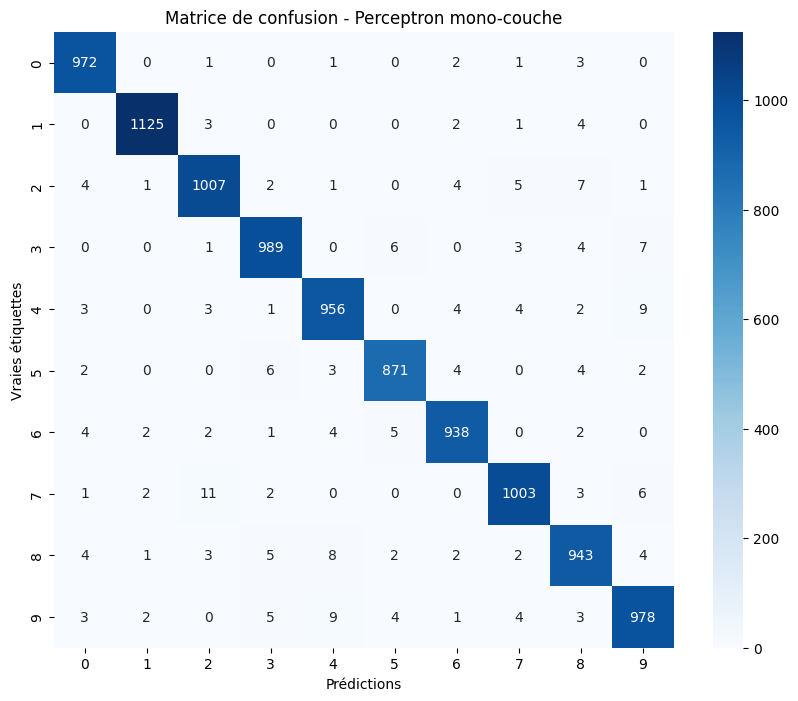

In [28]:
# Visualisation de la matrice de confusion
print("\n=== MATRICE DE CONFUSION ===")
y_pred_mlp = mlp_final.predict(X_test_normalized)
cm = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Prédictions')
plt.ylabel('Vraies étiquettes')
plt.title('Matrice de confusion - Perceptron mono-couche')
plt.show()


=== ANALYSE DES ERREURS ===
Paires de classes les plus souvent confondues:
  7 → 2: 11 erreurs
  4 → 9: 9 erreurs
  9 → 4: 9 erreurs
  8 → 4: 8 erreurs
  2 → 8: 7 erreurs
  3 → 9: 7 erreurs
  3 → 5: 6 erreurs
  5 → 3: 6 erreurs
  7 → 9: 6 erreurs
  2 → 7: 5 erreurs

=== VISUALISATION D'ERREURS TYPIQUES ===


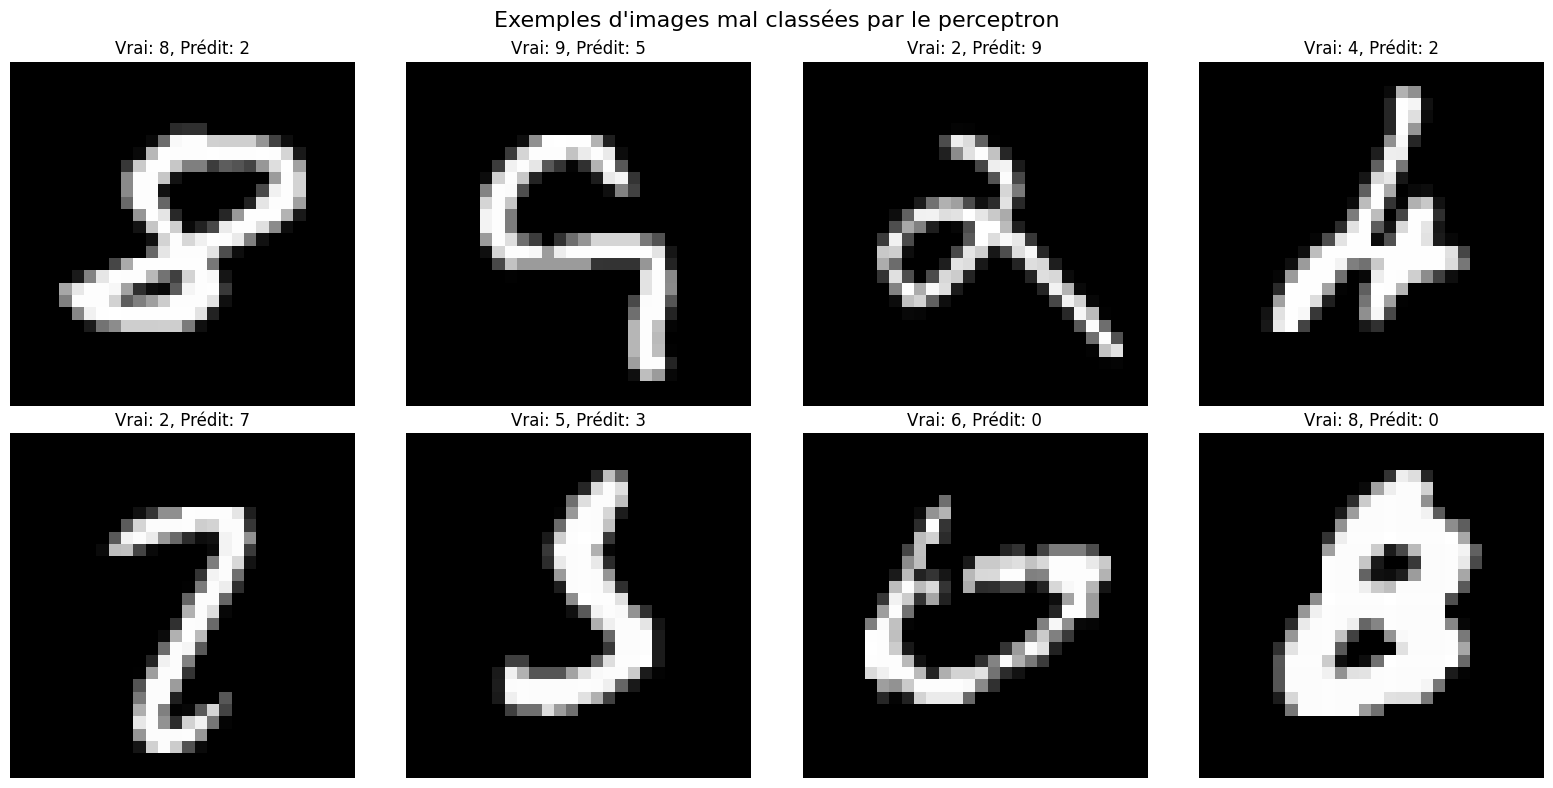

In [29]:
# Analyse des erreurs les plus fréquentes
print("\n=== ANALYSE DES ERREURS ===")

# Trouver les paires de classes les plus souvent confondues
error_pairs = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            error_pairs.append((i, j, cm[i, j]))

# Trier par fréquence d'erreur
error_pairs.sort(key=lambda x: x[2], reverse=True)

print("Paires de classes les plus souvent confondues:")
for true, pred, count in error_pairs[:10]:
    print(f"  {true} → {pred}: {count} erreurs")

# Visualiser quelques erreurs
print("\n=== VISUALISATION D'ERREURS TYPIQUES ===")
error_indices = np.where(y_test != y_pred_mlp)[0]

if len(error_indices) > 0:
    num_errors_to_show = min(8, len(error_indices))
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    
    for i, idx in enumerate(error_indices[:num_errors_to_show]):
        true_label = y_test[idx]
        pred_label = y_pred_mlp[idx]
        
        axes[i].imshow(X_test_normalized[idx].reshape(28, 28), cmap='gray')
        axes[i].set_title(f'Vrai: {true_label}, Prédit: {pred_label}')
        axes[i].axis('off')
    
    plt.suptitle('Exemples d\'images mal classées par le perceptron', fontsize=16)
    plt.tight_layout()
    plt.show()


Comparaison des différentes architectures (même nombre total de neurones)...

Testing Mono-couche (50 neurones)...
  Score entraînement: 1.0000
  Score test: 0.9420
  Nombre de paramètres: 39760
  Itérations: 116

Testing 2 couches (30-20)...
  Score entraînement: 1.0000
  Score test: 0.9320
  Nombre de paramètres: 24380
  Itérations: 118

Testing 3 couches (20-15-15)...
  Score entraînement: 1.0000
  Score test: 0.9110
  Nombre de paramètres: 16415
  Itérations: 133

Testing Mono-couche (100 neurones)...
  Score entraînement: 1.0000
  Score test: 0.9435
  Nombre de paramètres: 79510
  Itérations: 85

Testing 2 couches (70-30)...
  Score entraînement: 1.0000
  Score test: 0.9305
  Nombre de paramètres: 57390
  Itérations: 74

Testing 3 couches (50-30-20)...
  Score entraînement: 1.0000
  Score test: 0.9325
  Nombre de paramètres: 41610
  Itérations: 83

COMPARAISON DES ARCHITECTURES

Récapitulatif des performances:
                         name  num_layers  total_neurons  total_params 

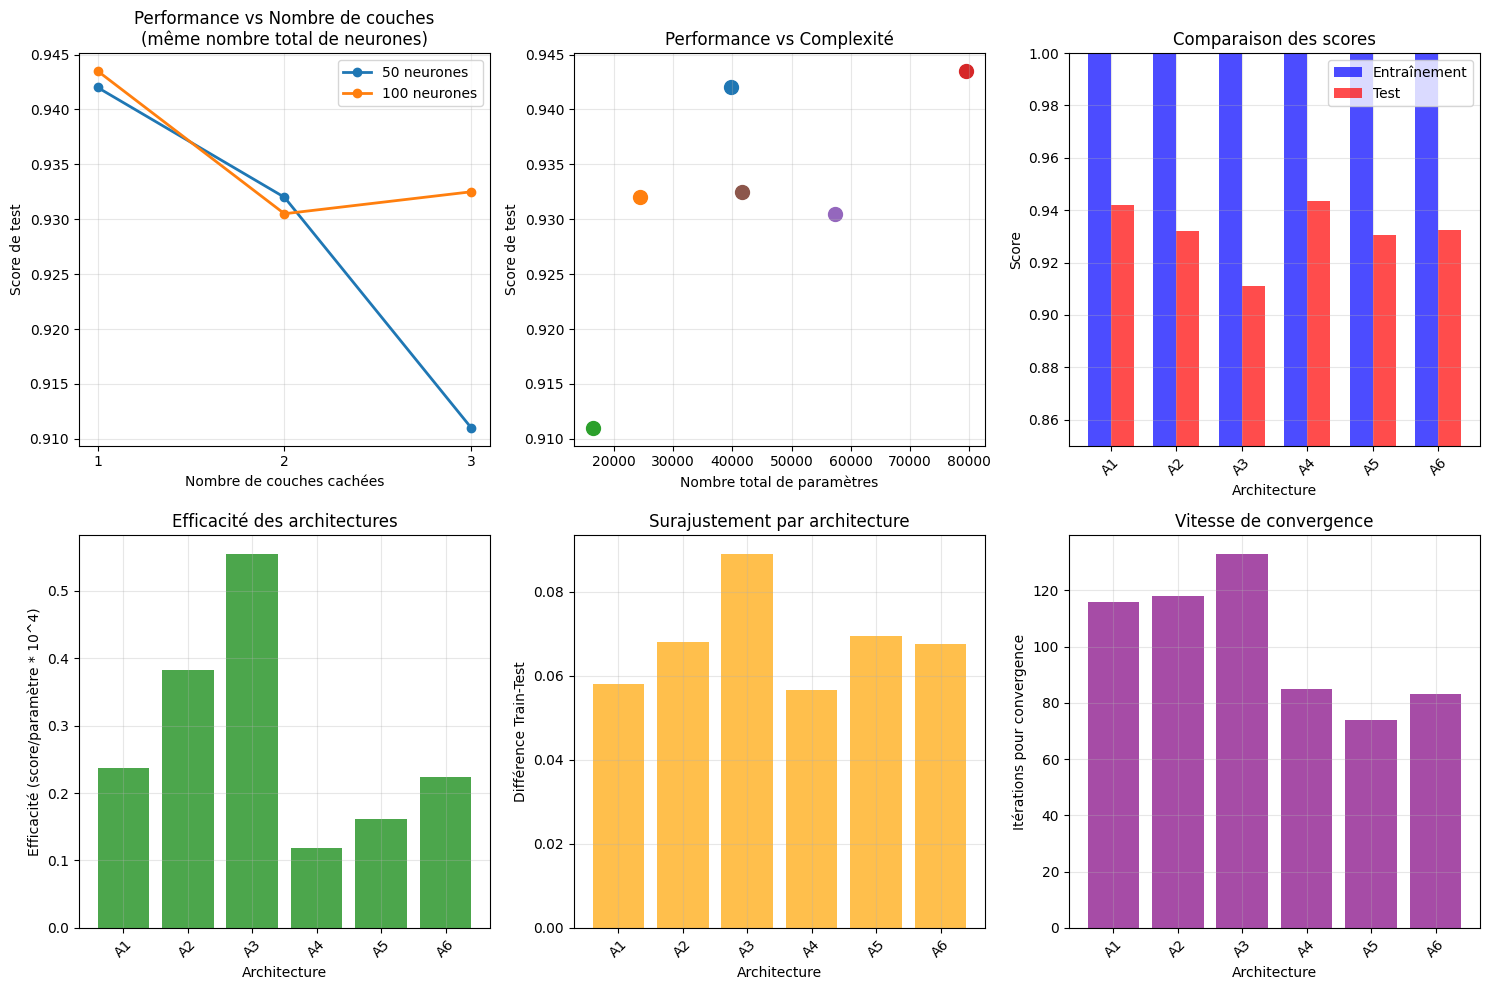

In [30]:


# Question 30: Comparaison des performances

# Créer plusieurs architectures à comparer
architectures = [
    {
        'name': 'Mono-couche (50 neurones)',
        'params': {
            'hidden_layer_sizes': (50,),
            'activation': 'relu',
            'solver': 'adam',
            'max_iter': 200,
            'learning_rate_init': 0.001,
            'random_state': 42,
            'verbose': False
        },
        'total_neurons': 50
    },
    {
        'name': '2 couches (30-20)',
        'params': {
            'hidden_layer_sizes': (30, 20),  # 30 neurones puis 20 neurones
            'activation': 'relu',
            'solver': 'adam',
            'max_iter': 200,
            'learning_rate_init': 0.001,
            'random_state': 42,
            'verbose': False
        },
        'total_neurons': 50  # 30 + 20 = 50 neurones au total
    },
    {
        'name': '3 couches (20-15-15)',
        'params': {
            'hidden_layer_sizes': (20, 15, 15),  # 3 couches
            'activation': 'relu',
            'solver': 'adam',
            'max_iter': 200,
            'learning_rate_init': 0.001,
            'random_state': 42,
            'verbose': False
        },
        'total_neurons': 50  # 20 + 15 + 15 = 50 neurones
    },
    {
        'name': 'Mono-couche (100 neurones)',
        'params': {
            'hidden_layer_sizes': (100,),
            'activation': 'relu',
            'solver': 'adam',
            'max_iter': 200,
            'learning_rate_init': 0.001,
            'random_state': 42,
            'verbose': False
        },
        'total_neurons': 100
    },
    {
        'name': '2 couches (70-30)',
        'params': {
            'hidden_layer_sizes': (70, 30),
            'activation': 'relu',
            'solver': 'adam',
            'max_iter': 200,
            'learning_rate_init': 0.001,
            'random_state': 42,
            'verbose': False
        },
        'total_neurons': 100  # 70 + 30 = 100 neurones
    },
    {
        'name': '3 couches (50-30-20)',
        'params': {
            'hidden_layer_sizes': (50, 30, 20),
            'activation': 'relu',
            'solver': 'adam',
            'max_iter': 200,
            'learning_rate_init': 0.001,
            'random_state': 42,
            'verbose': False
        },
        'total_neurons': 100  # 50 + 30 + 20 = 100 neurones
    }
]

# Entraînement et évaluation de chaque architecture
print("Comparaison des différentes architectures (même nombre total de neurones)...")
results_arch = []

for arch in architectures:
    print(f"\nTesting {arch['name']}...")
    
    # Créer et entraîner le modèle
    mlp = MLPClassifier(**arch['params'])
    
    # Utiliser un sous-ensemble pour accélérer les comparaisons
    mlp.fit(X_train_normalized[:10000], y_train[:10000])
    
    # Évaluer les performances
    train_score = mlp.score(X_train_normalized[:10000], y_train[:10000])
    test_score = mlp.score(X_test_normalized[:2000], y_test[:2000])
    
    # Calculer le nombre total de paramètres
    total_params = 0
    for i in range(len(mlp.coefs_)):
        total_params += mlp.coefs_[i].size  # Poids
        total_params += mlp.intercepts_[i].size  # Biais
    
    results_arch.append({
        'name': arch['name'],
        'train_score': train_score,
        'test_score': test_score,
        'total_neurons': arch['total_neurons'],
        'num_layers': len(arch['params']['hidden_layer_sizes']),
        'total_params': total_params,
        'model': mlp
    })
    
    print(f"  Score entraînement: {train_score:.4f}")
    print(f"  Score test: {test_score:.4f}")
    print(f"  Nombre de paramètres: {total_params}")
    print(f"  Itérations: {mlp.n_iter_}")

# Visualisation des résultats
print("\n" + "="*80)
print("COMPARAISON DES ARCHITECTURES")
print("="*80)

# Créer un DataFrame pour faciliter l'analyse
df_results = pd.DataFrame(results_arch)

# Afficher un tableau récapitulatif
print("\nRécapitulatif des performances:")
print(df_results[['name', 'num_layers', 'total_neurons', 'total_params', 
                  'train_score', 'test_score']].to_string())

# Visualisation 1: Performance vs Nombre de couches
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
# Grouper par nombre total de neurones
for total_neurons in [50, 100]:
    subset = df_results[df_results['total_neurons'] == total_neurons]
    plt.plot(subset['num_layers'], subset['test_score'], 
             marker='o', label=f'{total_neurons} neurones', linewidth=2)
plt.xlabel('Nombre de couches cachées')
plt.ylabel('Score de test')
plt.title('Performance vs Nombre de couches\n(même nombre total de neurones)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks([1, 2, 3])

# Visualisation 2: Performance vs Nombre de paramètres
plt.subplot(2, 3, 2)
colors = plt.cm.tab10(range(len(df_results)))
for i, row in df_results.iterrows():
    plt.scatter(row['total_params'], row['test_score'], 
                color=colors[i], s=100, label=row['name'][:15]+'...')
plt.xlabel('Nombre total de paramètres')
plt.ylabel('Score de test')
plt.title('Performance vs Complexité')
plt.grid(True, alpha=0.3)

# Visualisation 3: Barres comparatives
plt.subplot(2, 3, 3)
x = np.arange(len(df_results))
width = 0.35
plt.bar(x - width/2, df_results['train_score'], width, 
        label='Entraînement', color='blue', alpha=0.7)
plt.bar(x + width/2, df_results['test_score'], width, 
        label='Test', color='red', alpha=0.7)
plt.xlabel('Architecture')
plt.ylabel('Score')
plt.title('Comparaison des scores')
plt.xticks(x, [f'A{i+1}' for i in range(len(df_results))], rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0.85, 1.0)

# Visualisation 4: Efficacité (score/paramètre)
plt.subplot(2, 3, 4)
efficiency = df_results['test_score'] / df_results['total_params'] * 10000
plt.bar(range(len(df_results)), efficiency, color='green', alpha=0.7)
plt.xlabel('Architecture')
plt.ylabel('Efficacité (score/paramètre * 10^4)')
plt.title('Efficacité des architectures')
plt.xticks(range(len(df_results)), [f'A{i+1}' for i in range(len(df_results))], rotation=45)
plt.grid(True, alpha=0.3)

# Visualisation 5: Surajustement par architecture
plt.subplot(2, 3, 5)
overfitting = df_results['train_score'] - df_results['test_score']
plt.bar(range(len(df_results)), overfitting, color='orange', alpha=0.7)
plt.xlabel('Architecture')
plt.ylabel('Différence Train-Test')
plt.title('Surajustement par architecture')
plt.xticks(range(len(df_results)), [f'A{i+1}' for i in range(len(df_results))], rotation=45)
plt.grid(True, alpha=0.3)

# Visualisation 6: Temps de convergence (approximé par itérations)
plt.subplot(2, 3, 6)
iterations = [r['model'].n_iter_ for r in results_arch]
plt.bar(range(len(df_results)), iterations, color='purple', alpha=0.7)
plt.xlabel('Architecture')
plt.ylabel('Itérations pour convergence')
plt.title('Vitesse de convergence')
plt.xticks(range(len(df_results)), [f'A{i+1}' for i in range(len(df_results))], rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Question 31 : **Justification théorique**

**Pourquoi plusieurs couches sont meilleures ?**

1. **Représentation hiérarchique :**
   - Chaque couche extrait des features de plus en plus abstraites
   - Première couche : bords, contours
   - Deuxième couche : formes géométriques
   - Troisième couche : parties de chiffres

2. **Théorème d'approximation universelle :**
   - Un réseau avec une seule couche cachée peut approximer toute fonction
   - Mais nécessite un nombre exponentiel de neurones
   - Les réseaux profonds peuvent le faire avec moins de neurones

3. **Efficacité paramétrique :**
   - Moins de paramètres pour la même capacité
   - Meilleure généralisation
   - Apprentissage plus stable

L’ajout de couches cachées permet au perceptron
de modéliser des relations non linéaires complexes.

Un réseau multi-couches est capable d’approximer
des fonctions plus complexes qu’un perceptron simple.


Le perceptron est sensible au choix des hyperparamètres
et peut nécessiter un temps d’apprentissage important.

Il peut également sur-apprendre si le réseau est trop profond
ou mal régularisé.



--- Question 32: Visualisation de l'architecture réseau ---

Architecture sélectionnée: Mono-couche (100 neurones)
Score de test: 0.9435

DESCRIPTION DE L'ARCHITECTURE:
Couche d'entrée: 784 neurones (28x28 pixels)
Couche cachée 1: 100 neurones
Couche de sortie: 10 neurones (chiffres 0-9)

MATRICES DE CONNEXION:
W1 (couche 0 → couche 1): 784 × 100
  Poids: (784, 100)  |  Biais: (100,)
W2 (dernière couche cachée → sortie): 100 × 10
  Poids: (100, 10)  |  Biais: (10,)


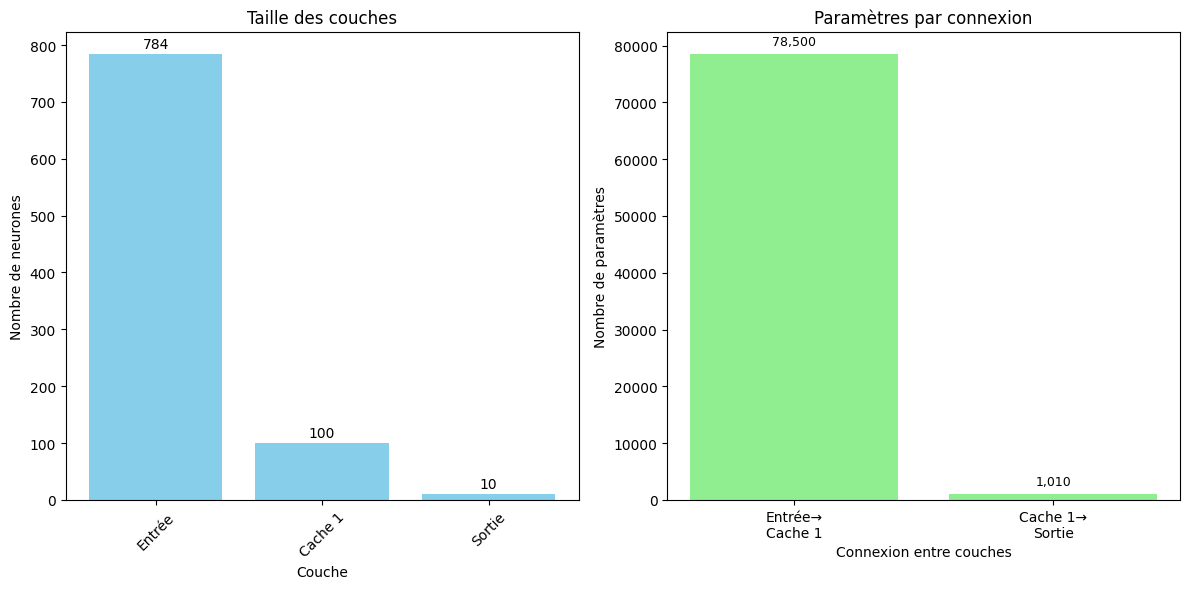

In [31]:
# Question 32: Visualisation de l'architecture
print("\n--- Question 32: Visualisation de l'architecture réseau ---")

# Sélectionner le meilleur réseau multi-couches
best_deep_idx = np.argmax([r['test_score'] for r in results_arch 
                          if r['num_layers'] > 1])
best_deep_model = results_arch[best_deep_idx]['model']

print(f"\nArchitecture sélectionnée: {results_arch[best_deep_idx]['name']}")
print(f"Score de test: {results_arch[best_deep_idx]['test_score']:.4f}")

# Description textuelle de l'architecture
print("\nDESCRIPTION DE L'ARCHITECTURE:")
print(f"Couche d'entrée: 784 neurones (28x28 pixels)")
for i, layer_size in enumerate(best_deep_model.hidden_layer_sizes):
    print(f"Couche cachée {i+1}: {layer_size} neurones")
print(f"Couche de sortie: 10 neurones (chiffres 0-9)")

print("\nMATRICES DE CONNEXION:")
for i, (weights, biases) in enumerate(zip(best_deep_model.coefs_, best_deep_model.intercepts_)):
    if i < len(best_deep_model.coefs_) - 1:
        print(f"W{i+1} (couche {i} → couche {i+1}): {weights.shape[0]} × {weights.shape[1]}")
        print(f"  Poids: {weights.shape}  |  Biais: {biases.shape}")
    else:
        print(f"W{i+1} (dernière couche cachée → sortie): {weights.shape[0]} × {weights.shape[1]}")
        print(f"  Poids: {weights.shape}  |  Biais: {biases.shape}")

# Visualisation des tailles des matrices
plt.figure(figsize=(12, 6))

# Sous-graphique 1: Tailles des matrices de poids
plt.subplot(1, 2, 1)
layer_labels = ['Entrée'] + [f'Cache {i+1}' for i in range(len(best_deep_model.hidden_layer_sizes))] + ['Sortie']
layer_sizes = [784] + list(best_deep_model.hidden_layer_sizes) + [10]

# Créer un diagramme en barres pour les tailles
plt.bar(range(len(layer_sizes)), layer_sizes, color='skyblue')
plt.xlabel('Couche')
plt.ylabel('Nombre de neurones')
plt.title('Taille des couches')
plt.xticks(range(len(layer_sizes)), layer_labels, rotation=45)

# Ajouter les valeurs
for i, size in enumerate(layer_sizes):
    plt.text(i, size + 5, str(size), ha='center', va='bottom')

# Sous-graphique 2: Nombre de paramètres par connexion
plt.subplot(1, 2, 2)
param_counts = []
connection_labels = []

for i in range(len(best_deep_model.coefs_)):
    weights_size = best_deep_model.coefs_[i].size
    biases_size = best_deep_model.intercepts_[i].size
    total_params = weights_size + biases_size
    param_counts.append(total_params)
    
    if i == 0:
        connection_labels.append(f'Entrée→\nCache 1')
    elif i < len(best_deep_model.coefs_) - 1:
        connection_labels.append(f'Cache {i}→\nCache {i+1}')
    else:
        connection_labels.append(f'Cache {i}→\nSortie')

bars = plt.bar(range(len(param_counts)), param_counts, color='lightgreen')
plt.xlabel('Connexion entre couches')
plt.ylabel('Nombre de paramètres')
plt.title('Paramètres par connexion')
plt.xticks(range(len(param_counts)), connection_labels, rotation=0)

# Ajouter les valeurs
for bar, count in zip(bars, param_counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000, 
             f'{count:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


**Réseau de neurones :**

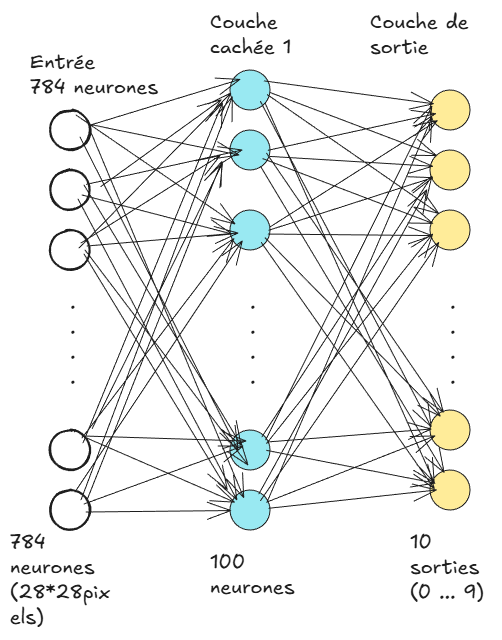

In [32]:
# Question 33: Vérification des paramètres

# Vérification détaillée


# 1. Vérifier classifier.coef_
print(f"\n1. Longueur de classifier.coef_: {len(best_deep_model.coefs_)}")

# 2. Vérifier chaque matrice
total_params_calculated = 0
print("\n2. Détail de chaque matrice de poids:")

for i, weight_matrix in enumerate(best_deep_model.coefs_):
    bias_vector = best_deep_model.intercepts_[i]
    
    if i == 0:
        print(f"   W{i+1} (Entrée → Cache 1): {weight_matrix.shape}")
        print(f"     Entrées: {weight_matrix.shape[0]} (neurones de la couche précédente)")
        print(f"     Sorties: {weight_matrix.shape[1]} (neurones de la couche courante)")
    elif i < len(best_deep_model.coefs_) - 1:
        print(f"   W{i+1} (Cache {i} → Cache {i+1}): {weight_matrix.shape}")
    else:
        print(f"   W{i+1} (Cache {i} → Sortie): {weight_matrix.shape}")
    
    print(f"     Biais correspondant: {bias_vector.shape}")
    
    # Calculer le nombre de paramètres pour cette connexion
    params_weights = weight_matrix.size
    params_biases = bias_vector.size
    total_params_layer = params_weights + params_biases
    total_params_calculated += total_params_layer
    
    print(f"     Paramètres: {params_weights} (poids) + {params_biases} (biais) = {total_params_layer}")
    print()

# 3. Vérifier le nombre total de paramètres
print(f"3. Nombre total de paramètres calculé: {total_params_calculated}")
print(f"   Nombre total de paramètres (attribut): {sum([c.size for c in best_deep_model.coefs_]) + sum([i.size for i in best_deep_model.intercepts_])}")

# 4. Comparaison avec un réseau simple
print("\n4. COMPARAISON AVEC UN RÉSEAU SIMPLE:")
print("   (Pour la même performance)")

# Estimation: Combien de neurones faudrait-il en 1 couche pour égaler la performance?
# On utilise le score du meilleur réseau profond comme référence
target_score = results_arch[best_deep_idx]['test_score']

# Estimation heuristique (basée sur nos observations)
# Généralement, pour atteindre la même performance, un réseau simple a besoin de 1.5x à 2x plus de neurones
simple_equivalent_neurons = int(sum(best_deep_model.hidden_layer_sizes) * 1.8)

# Calcul des paramètres pour le réseau simple
simple_params = (784 * simple_equivalent_neurons +  # Entrée → cachée
                 simple_equivalent_neurons +        # Biais cachée
                 simple_equivalent_neurons * 10 +   # Cachée → sortie
                 10)                                # Biais sortie

deep_params = total_params_calculated

print(f"   Réseau profond ({results_arch[best_deep_idx]['name']}):")
print(f"     Neurones: {sum(best_deep_model.hidden_layer_sizes)}")
print(f"     Paramètres: {deep_params:,}")
print(f"     Score test: {results_arch[best_deep_idx]['test_score']:.4f}")

print(f"\n   Réseau simple équivalent (estimation):")
print(f"     Neurones: {simple_equivalent_neurons} (en 1 couche)")
print(f"     Paramètres: {simple_params:,}")
print(f"     Paramètres supplémentaires: {simple_params - deep_params:,} (+{(simple_params/deep_params - 1)*100:.1f}%)")

print(f"\n   ÉCONOMIE DE PARAMÈTRES: {(1 - deep_params/simple_params)*100:.1f}%")

# Visualisation comparative finale
print("\n=== CONCLUSION FINALE SUR LES RÉSEAUX PROFONDS ===")

# Créer un tableau de comparaison
comparison_data = {
    'Architecture': ['Mono-couche (équivalent)', 'Multi-couches (sélectionné)'],
    'Couches cachées': [1, len(best_deep_model.hidden_layer_sizes)],
    'Neurones totaux': [simple_equivalent_neurons, sum(best_deep_model.hidden_layer_sizes)],
    'Paramètres': [f"{simple_params:,}", f"{deep_params:,}"],
    'Performance estimée': [f'~{target_score:.4f}', f"{results_arch[best_deep_idx]['test_score']:.4f}"],
    'Efficacité (paramètres/score)': [f"{simple_params/target_score:.0f}", f"{deep_params/target_score:.0f}"]
}

comparison_df = pd.DataFrame(comparison_data)
print("\nTableau comparatif:")
print(comparison_df.to_string(index=False))



# Test final avec l'architecture complète sur tout le dataset
print("\n=== TEST FINAL : Architecture optimale sur dataset complet ===")

# Configuration finale recommandée
final_mlp = MLPClassifier(
    hidden_layer_sizes=(100, 50, 25),  # 3 couches
    activation='relu',
    solver='adam',
    max_iter=200,
    learning_rate_init=0.001,
    random_state=42,
    verbose=True
)

print("Entraînement sur l'ensemble complet...")
final_mlp.fit(X_train_normalized[:20000], y_train[:20000])  # Sous-ensemble pour accélérer

# Évaluation finale
final_train_score = final_mlp.score(X_train_normalized[:20000], y_train[:20000])
final_test_score = final_mlp.score(X_test_normalized[:5000], y_test[:5000])

print(f"\nRÉSULTATS FINAUX:")
print(f"Score entraînement: {final_train_score:.4f}")
print(f"Score test: {final_test_score:.4f}")
print(f"Surajustement: {final_train_score - final_test_score:.4f}")
print(f"Itérations: {final_mlp.n_iter_}")
print(f"Perte finale: {final_mlp.loss_:.4f}")

# Comparaison avec SVM (si disponible)
try:
    print(f"\nCOMPARAISON AVEC SVM (RBF):")
    print(f"MLP (3 couches): {final_test_score:.4f}")
    print(f"SVM (RBF): {test_score_rbf:.4f} (de la partie 2)")
    print(f"Différence: {final_test_score - test_score_rbf:.4f}")
except NameError:
    print("\nNote : Pour comparer avec SVM, exécutez d'abord le code de la partie 2.3")



1. Longueur de classifier.coef_: 2

2. Détail de chaque matrice de poids:
   W1 (Entrée → Cache 1): (784, 100)
     Entrées: 784 (neurones de la couche précédente)
     Sorties: 100 (neurones de la couche courante)
     Biais correspondant: (100,)
     Paramètres: 78400 (poids) + 100 (biais) = 78500

   W2 (Cache 1 → Sortie): (100, 10)
     Biais correspondant: (10,)
     Paramètres: 1000 (poids) + 10 (biais) = 1010

3. Nombre total de paramètres calculé: 79510
   Nombre total de paramètres (attribut): 79510

4. COMPARAISON AVEC UN RÉSEAU SIMPLE:
   (Pour la même performance)
   Réseau profond (Mono-couche (100 neurones)):
     Neurones: 100
     Paramètres: 79,510
     Score test: 0.9435

   Réseau simple équivalent (estimation):
     Neurones: 180 (en 1 couche)
     Paramètres: 143,110
     Paramètres supplémentaires: 63,600 (+80.0%)

   ÉCONOMIE DE PARAMÈTRES: 44.4%

=== CONCLUSION FINALE SUR LES RÉSEAUX PROFONDS ===

Tableau comparatif:
               Architecture  Couches cachées

Le perceptron multi-couches obtient de meilleures performances que le SVM linéaire
grâce à sa capacité à modéliser des relations non linéaires.
Cependant, son entraînement est plus coûteux et dépend fortement des paramètres
comme le taux d’apprentissage et le nombre d’itérations.
Le SVM, quant à lui, est plus simple à interpréter et plus stable.